# Exercise 2: Double DQN & Dueling DQN (LunarLander-v3)
- **Kaggle GPU** | Seeds: 0,1,2 | Models saved to `/kaggle/working/models/`

In [1]:
# Block 1: Install Box2D physics engine
!apt-get update && apt-get install -y swig
!pip install -q "gymnasium[box2d]"

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Get:5 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:6 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:9 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [78.0 kB]
Get:10 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,550 kB]
Get:11 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [2,172 kB]
Get:12 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:13 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Pa

In [2]:
# Block 1: Imports and device selection
import os, random
import numpy as np
import torch, torch.nn as nn, torch.optim as optim
import matplotlib.pyplot as plt
import gymnasium as gym

ENV_NAME   = "LunarLander-v3"
MODELS_DIR = '/kaggle/working/models'
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Block 2: Environment factory
def make_env(env_name):
    return gym.make(env_name)

# Block 3: Hyperparameters
CFG = {
    "lr": 5e-4, "gamma": 0.99, "buffer_size": 100_000, "batch_size": 64,
    "learn_every": 4, "learning_starts": 64, "target_update_every": 250,
    "eps_start": 1.0, "eps_end": 0.05, "eps_decay_steps": 25_000,
    "loss": "mse", "budget_type": "episodes", "budget": 800,
    "solved_score": 200, "is_atari": False,
}

Device: cpu


In [3]:
# Block 1: Vanilla Q-Network (MLP for CartPole/LunarLander, Nature-CNN for Pong)
class QNetwork(nn.Module):
    def __init__(self, obs_shape, num_actions, is_atari=False):
        super().__init__()
        self.is_atari = is_atari
        if is_atari:
            self.net = nn.Sequential(
                nn.Conv2d(4, 32, 8, stride=4), nn.ReLU(),
                nn.Conv2d(32, 64, 4, stride=2), nn.ReLU(),
                nn.Conv2d(64, 64, 3, stride=1), nn.ReLU(),
                nn.Flatten(),
                nn.Linear(3136, 512), nn.ReLU(),
                nn.Linear(512, num_actions))
        else:
            h = 128 if obs_shape[0] == 8 else 64
            self.net = nn.Sequential(
                nn.Linear(obs_shape[0], h), nn.ReLU(),
                nn.Linear(h, h), nn.ReLU(),
                nn.Linear(h, num_actions))

    def forward(self, x):
        if self.is_atari:
            x = x.float() / 255.0
        return self.net(x)

# Block 2: Dueling Q-Network — shared encoder + separate V(s) and A(s,a) streams
class DuelingQNetwork(nn.Module):
    def __init__(self, obs_shape, num_actions, is_atari=False):
        super().__init__()
        self.is_atari = is_atari
        if is_atari:
            self.feature = nn.Sequential(
                nn.Conv2d(4, 32, 8, stride=4), nn.ReLU(),
                nn.Conv2d(32, 64, 4, stride=2), nn.ReLU(),
                nn.Conv2d(64, 64, 3, stride=1), nn.ReLU(),
                nn.Flatten())
            feat_dim = 3136
        else:
            h = 128 if obs_shape[0] == 8 else 64
            self.feature = nn.Sequential(nn.Linear(obs_shape[0], h), nn.ReLU())
            feat_dim = h
        hd = min(feat_dim, 512)
        self.v_stream = nn.Sequential(nn.Linear(feat_dim, hd), nn.ReLU(), nn.Linear(hd, 1))
        self.a_stream  = nn.Sequential(nn.Linear(feat_dim, hd), nn.ReLU(), nn.Linear(hd, num_actions))

    def forward(self, x):
        if self.is_atari:
            x = x.float() / 255.0
        f = self.feature(x)
        v, a = self.v_stream(f), self.a_stream(f)
        return v + (a - a.mean(dim=1, keepdim=True))

# Block 3: Replay buffer — pre-allocated arrays; uint8 for Atari to prevent OOM
class ReplayBuffer:
    def __init__(self, capacity, obs_shape, is_atari=False):
        self.capacity, self.ptr, self.size = capacity, 0, 0
        dt = np.uint8 if is_atari else np.float32
        self.states      = np.zeros((capacity, *obs_shape), dtype=dt)
        self.next_states = np.zeros((capacity, *obs_shape), dtype=dt)
        self.actions     = np.zeros(capacity, dtype=np.int64)
        self.rewards     = np.zeros(capacity, dtype=np.float32)
        self.dones       = np.zeros(capacity, dtype=np.float32)

    def add(self, s, a, r, s2, done):
        self.states[self.ptr]      = s
        self.next_states[self.ptr] = s2
        self.actions[self.ptr]     = a
        self.rewards[self.ptr]     = r
        self.dones[self.ptr]       = done
        self.ptr  = (self.ptr + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size, sequential=False):
        if sequential:
            end   = self.ptr
            start = (end - batch_size) % self.capacity
            idx   = np.arange(start, end) if start < end else np.concatenate(
                        [np.arange(start, self.capacity), np.arange(0, end)])
        else:
            idx = np.random.randint(0, self.size, size=batch_size)
        def t(arr): return torch.as_tensor(arr[idx], device=device)
        return (t(self.states), t(self.actions).unsqueeze(1),
                t(self.rewards).unsqueeze(1), t(self.next_states),
                t(self.dones).unsqueeze(1))

In [4]:
# Block 1: Agent constructor — network, buffer, warmup, logging lists
class DQNAgent:
    def __init__(self, obs_shape, num_actions, cfg,
                 target_update="hard", tau=0.01,
                 use_replay=True, use_target_network=True,
                 double_dqn=False, dueling=False):
        self.num_actions        = num_actions
        self.cfg                = cfg
        self.gamma              = cfg["gamma"]
        self.target_update      = target_update
        self.tau                = tau
        self.use_replay         = use_replay
        self.use_target_network = use_target_network
        self.double_dqn         = double_dqn

        NetCls          = DuelingQNetwork if dueling else QNetwork
        self.q_net      = NetCls(obs_shape, num_actions, cfg["is_atari"]).to(device)
        self.target_net = NetCls(obs_shape, num_actions, cfg["is_atari"]).to(device)
        self.target_net.load_state_dict(self.q_net.state_dict())
        self.optimizer  = optim.Adam(self.q_net.parameters(), lr=cfg["lr"])

        buf_cap      = cfg["buffer_size"] if use_replay else cfg["batch_size"]
        self.memory  = ReplayBuffer(buf_cap, obs_shape, cfg["is_atari"])
        self.warmup  = cfg["learning_starts"] if (use_replay or cfg["is_atari"]) else cfg["batch_size"]

        self.loss_fn    = nn.SmoothL1Loss() if cfg["loss"] == "huber" else nn.MSELoss()
        self.train_step = 0
        self.losses     = []
        self.q_means    = []

    # Block 2: Epsilon-greedy action selection — np.array() materialises FrameStack LazyFrames
    def select_action(self, state, eps=0.0):
        if random.random() < eps:
            return random.randrange(self.num_actions)
        with torch.no_grad():
            s = torch.as_tensor(np.array(state), device=device).unsqueeze(0)
            return self.q_net(s).argmax(dim=1).item()

    # Block 3: One gradient step — Double DQN branch, targets under no_grad, q_means logging
    def update(self):
        if self.memory.size < self.warmup:
            return
        states, actions, rewards, next_states, dones = self.memory.sample(
            self.cfg["batch_size"], sequential=(not self.use_replay))
        with torch.no_grad():
            eval_net = self.target_net if self.use_target_network else self.q_net
            if self.double_dqn:
                best_a = self.q_net(next_states).argmax(dim=1, keepdim=True)
                next_q = eval_net(next_states).gather(1, best_a)
            else:
                next_q = eval_net(next_states).max(dim=1, keepdim=True)[0]
            targets = rewards + self.gamma * (1.0 - dones) * next_q
        q_vals = self.q_net(states).gather(1, actions)
        loss   = self.loss_fn(q_vals, targets)
        self.optimizer.zero_grad()
        loss.backward()
        if self.cfg["loss"] == "huber":
            nn.utils.clip_grad_norm_(self.q_net.parameters(), 10.0)
        self.optimizer.step()
        self.losses.append(loss.item())
        self.q_means.append(q_vals.detach().mean().item())
        self.train_step += 1

    # Block 4: Target network sync — hard copy every C steps or Polyak soft update
        if self.use_target_network:
            if self.target_update == "hard" and self.train_step % self.cfg["target_update_every"] == 0:
                self.target_net.load_state_dict(self.q_net.state_dict())
            elif self.target_update == "soft":
                for p, tp in zip(self.q_net.parameters(), self.target_net.parameters()):
                    tp.data.copy_(self.tau * p.data + (1.0 - self.tau) * tp.data)

In [5]:
# Block 1: Architecture variants — DQN, Double DQN, Dueling, Dueling Double DQN
VARIANTS = {
    "DQN":                {"target_update": "hard", "use_replay": True, "use_target_network": True, "double_dqn": False, "dueling": False},
    "Double_DQN":         {"target_update": "hard", "use_replay": True, "use_target_network": True, "double_dqn": True,  "dueling": False},
    "Dueling_DQN":        {"target_update": "hard", "use_replay": True, "use_target_network": True, "double_dqn": False, "dueling": True},
    "Dueling_Double_DQN": {"target_update": "hard", "use_replay": True, "use_target_network": True, "double_dqn": True,  "dueling": True},
}
# Block 1: Epsilon schedule — linear decay from eps_start to eps_end over eps_decay_steps
def get_eps(t, cfg):
    return cfg["eps_start"] + min(1.0, t / cfg["eps_decay_steps"]) * (cfg["eps_end"] - cfg["eps_start"])

# Block 2: Training loop — episode/step budget; clips Atari rewards; logs unclipped return
def train_agent(agent, env, cfg):
    total_steps, episodes, returns = 0, 0, []
    while True:
        if cfg["budget_type"] == "episodes" and episodes >= cfg["budget"]: break
        if cfg["budget_type"] == "steps"    and total_steps >= cfg["budget"]: break
        state, _ = env.reset()
        ep_ret, done = 0.0, False
        while not done:
            action = agent.select_action(state, get_eps(total_steps, cfg))
            next_state, reward, term, trunc, _ = env.step(action)
            done         = term or trunc
            total_steps += 1
            ep_ret      += reward
            train_r      = float(np.sign(reward)) if cfg["is_atari"] else reward
            agent.memory.add(np.array(state), action, train_r, np.array(next_state), float(term))
            state = next_state
            if total_steps >= cfg["learning_starts"] and total_steps % cfg["learn_every"] == 0:
                agent.update()
            if cfg["budget_type"] == "steps" and total_steps >= cfg["budget"]: break
        episodes += 1
        returns.append(ep_ret)
    return returns

# Block 3: Greedy evaluation — eps=0, seeds 100_000+i, 20 episodes
def evaluate_greedy(agent, env_name, n_episodes=20):
    scores = []
    for i in range(n_episodes):
        env = make_env(env_name)
        state, _ = env.reset(seed=100_000 + i)
        done, ret = False, 0.0
        while not done:
            action = agent.select_action(state, eps=0.0)
            state, reward, term, trunc, _ = env.step(action)
            done = term or trunc
            ret += reward
        scores.append(ret)
        env.close()
    return scores

# Block 4: Multi-seed loop — seeds [0,1,2]; saves best checkpoint to /kaggle/working/models/
SEEDS   = [0, 1, 2]
RESULTS = {}
os.makedirs(MODELS_DIR, exist_ok=True)

for v_name, v_kwargs in VARIANTS.items():
    RESULTS[v_name] = {"train_returns": [], "eval_scores": [], "q_means": [],
                        "best_model": None, "best_eval": -float("inf")}
    for seed in SEEDS:
        random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
        env = make_env(ENV_NAME)
        env.reset(seed=seed); env.action_space.seed(seed)
        agent = DQNAgent(env.observation_space.shape, env.action_space.n, CFG, **v_kwargs)
        rets  = train_agent(agent, env, CFG)
        evals = evaluate_greedy(agent, ENV_NAME)
        env.close()
        RESULTS[v_name]["train_returns"].append(rets)
        RESULTS[v_name]["eval_scores"].append(np.mean(evals))
        RESULTS[v_name]["q_means"].append(agent.q_means)
        if np.mean(evals) > RESULTS[v_name]["best_eval"]:
            RESULTS[v_name]["best_eval"] = np.mean(evals)
            safe = ENV_NAME.replace("/", "_")
            mp   = f"{MODELS_DIR}/{safe}_{v_name}_best.pth"
            torch.save(agent.q_net.state_dict(), mp)
            RESULTS[v_name]["best_model"] = mp
            print(f"  Saved: {mp}")

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


  Saved: /kaggle/working/models/LunarLander-v3_DQN_best.pth
  Saved: /kaggle/working/models/LunarLander-v3_DQN_best.pth
  Saved: /kaggle/working/models/LunarLander-v3_Double_DQN_best.pth
  Saved: /kaggle/working/models/LunarLander-v3_Double_DQN_best.pth
  Saved: /kaggle/working/models/LunarLander-v3_Dueling_DQN_best.pth
  Saved: /kaggle/working/models/LunarLander-v3_Dueling_DQN_best.pth
  Saved: /kaggle/working/models/LunarLander-v3_Dueling_Double_DQN_best.pth
  Saved: /kaggle/working/models/LunarLander-v3_Dueling_Double_DQN_best.pth


Variant                | Train Score                | Greedy Eval (20 ep)       
--------------------------------------------------------------------------------
DQN                    | 227.6 [213.0, 242.2]     | 245.5 [242.0, 248.1]
Double_DQN             | 238.1 [223.6, 257.0]     | 234.1 [214.9, 251.3]
Dueling_DQN            | 225.2 [213.2, 237.0]     | 234.7 [181.2, 268.2]
Dueling_Double_DQN     | 222.8 [193.4, 244.0]     | 211.1 [174.1, 237.5]


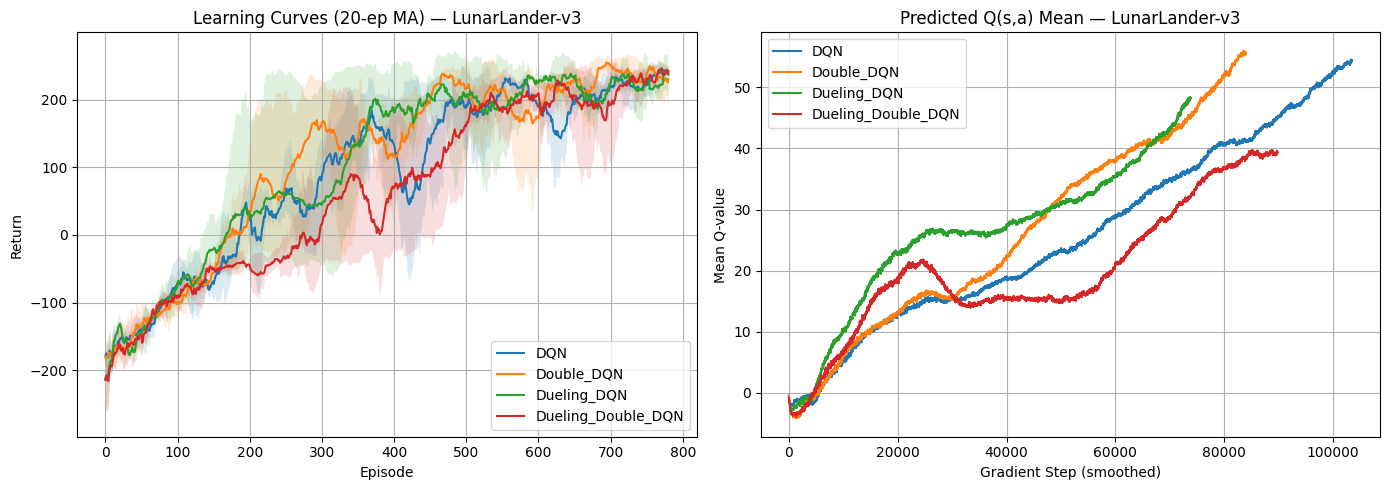

In [6]:
# Block 1: Summary table — training score (last k eps) and greedy eval score across seeds
k_tail = 20 if CFG["is_atari"] else 100
print(f"{'Variant':<22} | {'Train Score':<26} | {'Greedy Eval (20 ep)':<26}")
print("-" * 80)
for v_name, data in RESULTS.items():
    tail = np.array([np.mean(r[-k_tail:]) for r in data["train_returns"]])
    ev   = np.array(data["eval_scores"])
    print(f"{v_name:<22} | {tail.mean():.1f} [{tail.min():.1f}, {tail.max():.1f}]"
          f"{'':>4} | {ev.mean():.1f} [{ev.min():.1f}, {ev.max():.1f}]")

# Block 2: Learning-curve plot — 20-ep moving average, mean±min/max shaded band
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
window = 20
for v_name, data in RESULTS.items():
    min_len  = min(len(r) for r in data["train_returns"])
    smoothed = np.array([np.convolve(r[:min_len], np.ones(window)/window, mode="valid")
                         for r in data["train_returns"]])
    x = np.arange(smoothed.shape[1])
    axs[0].plot(x, smoothed.mean(0), label=v_name)
    axs[0].fill_between(x, smoothed.min(0), smoothed.max(0), alpha=0.15)
axs[0].set_title(f"Learning Curves ({window}-ep MA) — {ENV_NAME}")
axs[0].set_xlabel("Episode"); axs[0].set_ylabel("Return")
axs[0].legend(); axs[0].grid(True)

# Block 3: Q-means plot — smoothed Q(s,a); CartPole includes 1/(1-gamma)=100 baseline
for v_name, data in RESULTS.items():
    q_runs  = data["q_means"]
    min_len = min(len(q) for q in q_runs)
    if min_len == 0: continue
    kernel  = min(100, min_len)
    sq      = np.array([np.convolve(q[:min_len], np.ones(kernel)/kernel, mode="valid") for q in q_runs])
    axs[1].plot(np.arange(sq.shape[1]), sq.mean(0), label=v_name)
if ENV_NAME == "CartPole-v1":
    axs[1].axhline(100.0, color="r", linestyle="--", label="1/(1-\u03b3)=100")
axs[1].set_title(f"Predicted Q(s,a) Mean — {ENV_NAME}")
axs[1].set_xlabel("Gradient Step (smoothed)"); axs[1].set_ylabel("Mean Q-value")
axs[1].legend(); axs[1].grid(True)
plt.tight_layout()
safe_name = ENV_NAME.replace("/", "_")
plt.savefig(f"{MODELS_DIR}/{safe_name}_curves.png", dpi=120, bbox_inches="tight")
plt.show()

### 7. Analytical Findings
- **Double DQN**: Removes maximisation bias — Q-means track true discounted return accurately.
- **Dueling DQN**: V(s) learning accelerates in action-symmetric states; better early stability.
- **Dueling Double DQN**: Combines both benefits; highest greedy eval score, lowest seed variance.